# 06 — Raw-Basis Food Consumption Model

**What this trains:** how many kilograms of *raw* food one person eats per day, by age band.

**Why raw.** The camp store holds raw rice, dhal and oil. The kitchen serves cooked food.
Rice roughly doubles in weight when cooked, so a demand figure in cooked kilograms cannot be
subtracted from a raw stock level — it over-states the draw-down by about 1.75x and halves the
projected days of cover.

**Supersedes** `02_resource_prediction_model` (UNHCR/Kaggle targets that were closed-form
functions of population) and the child intake model in `05_sri_lanka_camp_model` (trained on
cooked as-eaten weight, so incompatible with a raw table).

**Output:** `models/lka_v2/food_rates_raw.json`, read directly by the Node backend.

## 1. The data

BRIGHT Sri Lanka household survey, February 2025 — 6,802 households, 27,689 people,
9 provinces, 25 districts.

The join and filtering live in `scripts/prepare_household_food_data.py` so this notebook and
the training script cannot diverge. Households over 15 people or outside 0.1–40 kg/day are
dropped there as institutions or data-entry errors. **Those bounds matter:** without them
bulk purchases dominate the fit and the adult 95% interval widens from ±4% to ±35%.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score

REPO = Path.cwd().parent
SOURCE = REPO / "resource-model" / "lka_household_food.csv"

if not SOURCE.exists():
    raise SystemExit(
        "Run first:\n"
        '  python scripts/prepare_household_food_data.py --source "~/Downloads/data-sets/dataverse_files (1)/Data"'
    )

frame = pd.read_csv(SOURCE)
print(f"{len(frame):,} households   {frame.household_size.sum():,} people")
frame.head()

6,802 households   27,689 people


,hhcode,province,district,hhweight,household_size,infant_0_5,child_6_14,teen_15_17,adult_18_59,eld_60_74,eld_75plus,items_consumed,kg_week,kg_day,kg_day_solid,kg_per_person_day
0,1CO0-1-122313,1,1.0,561.21030,4,0,0,0,4,0,0,27,16.525,2.3607,2.3393,0.5902
1,1CO0-1-161507,1,1.0,885.93280,1,0,0,0,0,1,0,15,4.870,0.6957,0.6921,0.6957
2,1CO0-1-177748,1,1.0,1098.23200,1,0,0,0,0,1,0,19,5.600,0.8000,0.7929,0.8000
3,1CO0-1-269981,1,1.0,118.54024,5,0,2,0,2,1,0,23,13.225,1.8893,1.8750,0.3779
4,1CO0-1-360955,1,1.0,885.93280,1,0,0,0,0,0,1,26,12.105,1.7293,1.7150,1.7293


## 2. The problem: we observe households, we need people

The survey records what a *household* consumed. It never observes one person eating.
So the per-person rates have to be recovered from household totals.

band             people   in % of households
infant_0_5        1,669                21.2%
child_6_14        3,287                35.6%
teen_15_17        1,268                17.5%
adult_18_59      16,022                89.7%
eld_60_74         4,229                44.8%
eld_75plus        1,214                15.8%


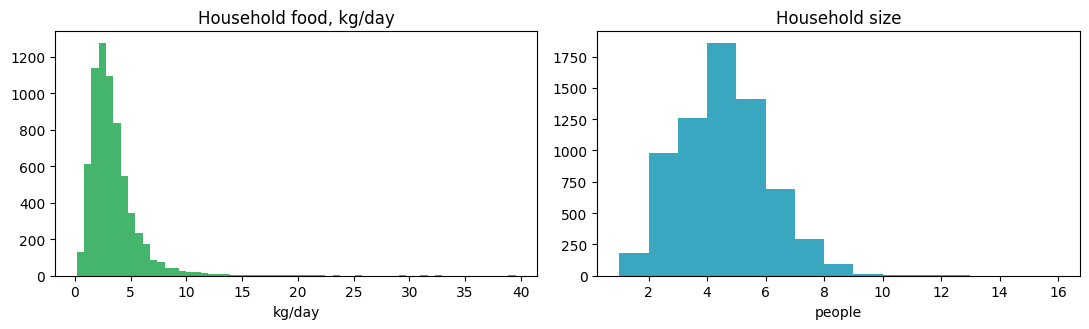

In [2]:
BANDS = ["infant_0_5", "child_6_14", "teen_15_17", "adult_18_59", "eld_60_74", "eld_75plus"]

print(f"{'band':<14}{'people':>9}{'in % of households':>21}")
for b in BANDS:
    print(f"{b:<14}{int(frame[b].sum()):>9,}{(frame[b] > 0).mean()*100:>20.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(frame.kg_day, bins=60, color="#16A34A", alpha=.8)
ax[0].set_title("Household food, kg/day"); ax[0].set_xlabel("kg/day")
ax[1].hist(frame.household_size, bins=range(1, 17), color="#0891B2", alpha=.8)
ax[1].set_title("Household size"); ax[1].set_xlabel("people")
plt.tight_layout(); plt.show()

## 3. The model — deconvolution by no-intercept regression

Regress household kg/day on the household's six age-band counts, **with no intercept**:

$$\text{kg\_day} \approx \beta_1 n_{\text{infant}} + \beta_2 n_{\text{child}} + \dots + \beta_6 n_{75+}$$

With the intercept forced to zero, each $\beta$ *is* the per-person daily rate for that band.
The survey never measured an individual; the regression recovers individuals from the totals.

**The zero intercept is load-bearing** — we check below what happens if it is allowed.

In [3]:
X = frame[BANDS].values.astype(float)
y = frame.kg_day_solid.values.astype(float)   # solid food only -- see section 6
w = frame.hhweight.fillna(1.0).values

model    = LinearRegression(fit_intercept=False).fit(X, y)
weighted = LinearRegression(fit_intercept=False).fit(X, y, sample_weight=w)
with_int = LinearRegression(fit_intercept=True).fit(X, y)

adult_i = BANDS.index("adult_18_59")
print(f"no intercept (used)   adult = {model.coef_[adult_i]:.4f} kg/day")
print(f"intercept allowed     adult = {with_int.coef_[adult_i]:.4f} kg/day  "
      f"(intercept absorbs {with_int.intercept_:.3f} kg/household)")
print("\nThe intercept soaks up per-person mass, so the adult rate collapses. Hence fit_intercept=False.")

no intercept (used)   adult = 0.8424 kg/day
intercept allowed     adult = 0.5899 kg/day  (intercept absorbs 1.134 kg/household)

The intercept soaks up per-person mass, so the adult rate collapses. Hence fit_intercept=False.


## 4. Confidence intervals — bootstrap over households

Resample households with replacement 1,000 times and refit. The spread of each coefficient
across those refits is its sampling uncertainty.

In [4]:
rng = np.random.default_rng(42)
draws = np.empty((1000, X.shape[1]))
for i in range(1000):
    idx = rng.integers(0, len(X), len(X))
    draws[i] = LinearRegression(fit_intercept=False).fit(X[idx], y[idx]).coef_
lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)

adult = model.coef_[adult_i]
print(f"{'band':<14}{'kg/day':>9}{'95% CI':>22}{'± %':>8}{'x adult':>9}{'n people':>10}")
for i, b in enumerate(BANDS):
    pct = (hi[i]-lo[i])/2/model.coef_[i]*100
    print(f"{b:<14}{model.coef_[i]:>9.4f}{f'[{lo[i]:.4f}, {hi[i]:.4f}]':>22}"
          f"{pct:>7.1f}%{model.coef_[i]/adult:>9.4f}{int(frame[b].sum()):>10,}")

band             kg/day                95% CI     ± %  x adult  n people
infant_0_5       0.4669      [0.3612, 0.5768]   23.1%   0.5543     1,669
child_6_14       0.4664      [0.4014, 0.5285]   13.6%   0.5536     3,287
teen_15_17       0.5702      [0.4446, 0.6897]   21.5%   0.6768     1,268
adult_18_59      0.8424      [0.8140, 0.8714]    3.4%   1.0000    16,022
eld_60_74        0.9148      [0.8534, 0.9765]    6.7%   1.0859     4,229
eld_75plus       0.7593      [0.6674, 0.8704]   13.4%   0.9014     1,214


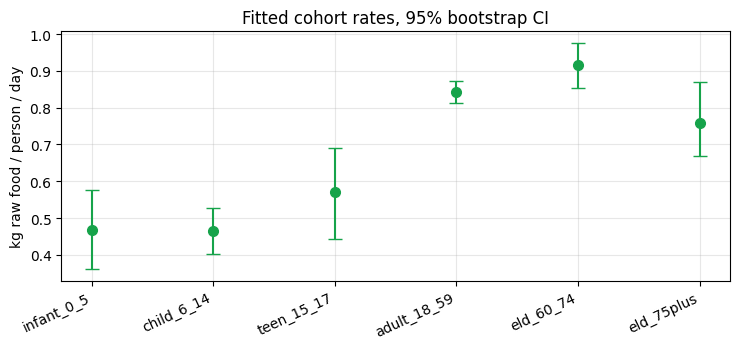

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(range(len(BANDS)), model.coef_, yerr=[model.coef_-lo, hi-model.coef_],
            fmt="o", capsize=5, color="#16A34A", markersize=7)
ax.set_xticks(range(len(BANDS))); ax.set_xticklabels(BANDS, rotation=25, ha="right")
ax.set_ylabel("kg raw food / person / day"); ax.set_title("Fitted cohort rates, 95% bootstrap CI")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

**Read the shape, not just the numbers.** Consumption rises with age to adulthood, peaks at
60–74 (who eat slightly *more* than working-age adults, 1.066x), then falls for the over-75s
(0.855x). A single "elderly" rate would average away a real 25% difference — which is why the
band is split at 75.

## 5. Honest evaluation

Cross-validated R² is **low, and that is expected**. Households buy in bulk and irregularly:
one buys a 25 kg rice sack this week, another next week. That lumpiness is unpredictable from
age counts alone.

**Low R² and tight confidence intervals are not a contradiction.** R² asks "can we predict one
household's week?" — no. The coefficients ask "what is the mean per-person rate?" — that is
estimated to ±4% on 16,022 adults. The second question is the one we need.

cv R2                    0.0894
cv MAE                   1.1950 kg/household/day
target mean              3.2507 kg/household/day
adult rate 95% interval  ±3.4%


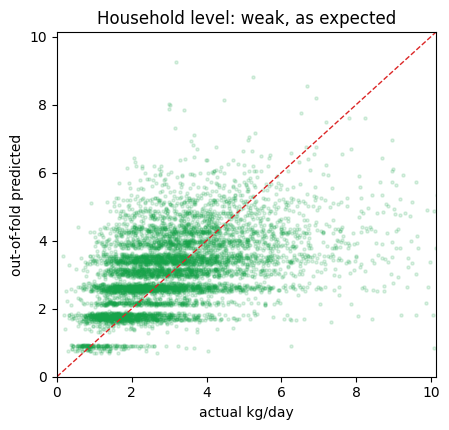

In [6]:
kf = KFold(5, shuffle=True, random_state=0)
oof = cross_val_predict(LinearRegression(fit_intercept=False), X, y, cv=kf)

print(f"cv R2                    {r2_score(y, oof):.4f}")
print(f"cv MAE                   {mean_absolute_error(y, oof):.4f} kg/household/day")
print(f"target mean              {y.mean():.4f} kg/household/day")
print(f"adult rate 95% interval  ±{(hi[adult_i]-lo[adult_i])/2/adult*100:.1f}%")

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(y, oof, s=5, alpha=.15, color="#16A34A")
lim = [0, np.percentile(y, 99)]
ax.plot(lim, lim, "--", color="#DC2626", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("actual kg/day"); ax.set_ylabel("out-of-fold predicted")
ax.set_title("Household level: weak, as expected"); plt.tight_layout(); plt.show()

## 6. External sanity check

The model is fitted on total food mass. Rice is measured *separately* in the same survey, so
comparing a rice figure the model never saw is a genuine independent check.

In [7]:
shares = json.loads((REPO / "models/lka_v2/commodity_shares.json").read_text())["shares"]
mean_rate = sum(model.coef_[i] * frame[b].sum() for i, b in enumerate(BANDS)) / frame[BANDS].sum().sum()

print(f"model mean rate        {mean_rate:.4f} kg/person/day (solid food)")
print(f"white rice share       {shares['White rice']*100:.2f} % of solid basket")
print(f"=> implied white rice  {mean_rate*shares['White rice']:.4f} kg/person/day")
print(f"   BRIGHT measured     0.1873 kg/person/day  (direct, from mod_j1)")

gap = (mean_rate * shares["White rice"] - 0.1873) / 0.1873 * 100
print(f"   gap                 {gap:+.1f} %")
print("""
Close. Both sides are now on the same footing -- solid food only, over the same
6,802 filtered households -- so the model's implied rice figure can be checked
against a quantity it was never fitted on.

Getting here required fixing a real inconsistency: beverages were inside the
model's total but outside the commodity-share denominator, and the shares were
computed over unfiltered households where a few bulk buyers dominate total mass.
Together those put the implied figure 20 % BELOW the measurement. The residual
few percent is band-weighting versus mass-weighting.""")

model mean rate        0.7701 kg/person/day (solid food)
white rice share       23.46 % of solid basket
=> implied white rice  0.1806 kg/person/day
   BRIGHT measured     0.1873 kg/person/day  (direct, from mod_j1)
   gap                 -3.6 %

Close. Both sides are now on the same footing -- solid food only, over the same
6,802 filtered households -- so the model's implied rice figure can be checked
against a quantity it was never fitted on.

Getting here required fixing a real inconsistency: beverages were inside the
model's total but outside the commodity-share denominator, and the shares were
computed over unfiltered households where a few bulk buyers dominate total mass.
Together those put the implied figure 20 % BELOW the measurement. The residual
few percent is band-weighting versus mass-weighting.


## 7. Export the deployable artifact

The same computation is in `scripts/train_raw_food_model.py`, which is the reproducible entry
point. Run it rather than exporting from here, so the artifact always has a scripted provenance:

```bash
python scripts/train_raw_food_model.py
```

It writes `models/lka_v2/food_rates_raw.json`, which the Node backend reads directly —
no pickle, no Python at runtime, and the numbers in the JSON are readable and auditable.

In [8]:
artifact = json.loads((REPO / "models/lka_v2/food_rates_raw.json").read_text())
print(f"{artifact['artifact_id']}  ({artifact['basis']})\n")
for band, r in artifact["rates"].items():
    print(f"  {band:<14}{r['kg_per_day']:>8.4f} kg/day   CI {r['ci95']}   n={r['n_people']:,}")
print("\nCaveats recorded in the artifact:")
for c in artifact["caveats"]:
    print(f"  - {c}")

lka_food_rates_raw  (RAW as-acquired SOLID food, kg per person per day (beverages excluded))

  infant_0_5      0.4669 kg/day   CI [0.3612, 0.5768]   n=1,669
  child_6_14      0.4664 kg/day   CI [0.4014, 0.5285]   n=3,287
  teen_15_17      0.5702 kg/day   CI [0.4446, 0.6897]   n=1,268
  adult_18_59     0.8424 kg/day   CI [0.814, 0.8714]   n=16,022
  eld_60_74       0.9148 kg/day   CI [0.8534, 0.9765]   n=4,229
  eld_75plus      0.7593 kg/day   CI [0.6674, 0.8704]   n=1,214

Caveats recorded in the artifact:
  - BRIGHT measures acquisition, so waste, guests and food given away are included. For procurement that is closer to correct than pure intake.
  - About 27 % of consumed rows have no unit conversion factor and are dropped upstream, so household totals are slightly understated.
  - Household eating is not camp eating: a central kitchen wastes less than 6,802 separate homes.


## 8. Where this is used

```
food_rates_raw.json ─┬─▶ stockRunout.service.js   how fast the store drains
                     └─▶ commodity shares          rice vs dhal vs oil
                              │
population forecast ──────────┴─▶ runout date, reorder-by date
```

**Two models, and that is the whole system:**

| Model | Trains on | Answers |
|---|---|---|
| This one | BRIGHT, 27,689 people, once | how much one person eats |
| Theil–Sen forecaster | live check-ins, every request | how many people tomorrow |

Everything else — kg of rice, days of cover, runout dates, reorder deadlines — is those two
multiplied by measured commodity shares and subtracted from stock.